# When dengue outgrows the model: urban transmission regimes and season-ahead forecasting in Bangladesh

**Analysis notebook for the manuscript submitted to *City and Environment Interactions*.**

This notebook produces every number, table and data figure in the manuscript.

| Section | What it does |
|---|---|
| 0 | Setup, versions, data loading, Census 2022 covariates |
| 1 | Dataset characterisation |
| 2 | Urban gradient: incidence per 100,000, zero-case days, overdispersion vs. population density |
| 3 | Season timing (onset, peak, end, duration) per division and year |
| 4 | Spatial lead–lag between Dhaka and the other divisions |
| 5 | Lagged climate–dengue association by division (0–16 weeks) |
| 6 | Season-ahead, multi-horizon forecasting (h = 1, 7, 14 d), 2023–2025; level vs. level-anchored models; extrapolation diagnostic |
| 7 | Skill by division (urban core vs. rest) and moving-block bootstrap CIs |
| 8 | Feature-group ablation in both formulations (weather, calendar, Census covariates) |
| 9 | Outbreak early-warning alerts (sensitivity, precision, lead time) |
| 10 | Season-ahead conformalized quantile regression intervals |
| 11 | Export of every number used in the manuscript (`results/cei_results.json`) |

**Data.** Rahman, A. (2026). *Daily Dengue Data of Bangladesh 2022–2025* [Kaggle dataset, version 1, CC BY 4.0].
https://www.kaggle.com/datasets/brownsugar297/dengue-and-weather-data-bangladesh-20222025

**How to run on Kaggle**
1. Attach the dataset above (or upload `Dataset.csv`) to this notebook.
2. *Settings → Internet: On* (only needed for the optional pinned-version install in the next cell).
3. *Run All*. CPU is enough (≈ 10–20 min). Outputs go to `/kaggle/working/outputs/`.

> XGBoost results depend on the library version. The manuscript numbers were produced with
> xgboost 3.1.3, lightgbm 4.7.0, catboost 1.2.10 and scikit-learn 1.9.1. Install them with the next cell to reproduce exactly.


In [1]:
# Optional: pin the library versions used for the manuscript (needs Internet ON on Kaggle).
# Set PIN_VERSIONS = True, run this cell, then Run All again (Kaggle may ask you to restart the kernel).
PIN_VERSIONS = True
if PIN_VERSIONS:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "xgboost==3.1.3", "lightgbm==4.7.0", "catboost==1.2.10", "scikit-learn==1.9.1"], check=True)

## 0. Setup

In [2]:
import os, glob, json, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, lightgbm, catboost
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, LGBMClassifier
from catboost import CatBoostRegressor

RNG = 42
np.random.seed(RNG)
VERSIONS = {"python": __import__("sys").version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "lightgbm": lightgbm.__version__, "catboost": catboost.__version__}
print(VERSIONS)
if xgboost.__version__ != "3.1.3":
    print("NOTE: xgboost is not 3.1.3 -> XGBoost-based numbers can differ slightly from the manuscript.")

# Output folders (Kaggle: /kaggle/working is writable)
BASE_OUT = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else os.path.join(os.getcwd(), "outputs")
FIG = os.path.join(BASE_OUT, "figures"); TAB = os.path.join(BASE_OUT, "tables"); RES = os.path.join(BASE_OUT, "results")
for p in (FIG, TAB, RES): os.makedirs(p, exist_ok=True)

# Locate Dataset.csv (Kaggle input, current folder, or ./data)
cands = (glob.glob("/kaggle/input/**/Dataset.csv", recursive=True) + glob.glob("Dataset.csv")
         + glob.glob("data/Dataset.csv") + glob.glob("../data/Dataset.csv") + glob.glob("/kaggle/input/**/*.csv", recursive=True))
DATA_PATH = os.environ.get("DENGUE_CSV", cands[0] if cands else "Dataset.csv")
print("Using data file:", DATA_PATH)

import matplotlib.dates as mdates
# Publication settings (Elsevier artwork guide): vector PDF with embedded TrueType fonts,
# 600-dpi PNG/TIFF (combination art needs >= 500 dpi), full-width figures 7.48 in = 190 mm,
# no text smaller than 7.5 pt at final size.
FULL_W = 7.48
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.labelsize": 9,
                     "figure.dpi": 110, "savefig.dpi": 600, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "font.family": "DejaVu Sans"})
URBAN_C, REST_C = "#B2182B", "#4D4D4D"
R = {"versions": VERSIONS}   # every number used in the manuscript is collected here
def savefig(fig, name):
    kw = dict(bbox_inches="tight", pad_inches=0.03, facecolor="white")
    fig.savefig(os.path.join(FIG, name + ".pdf"), **kw)                      # vector, preferred for submission
    fig.savefig(os.path.join(FIG, name + ".png"), dpi=600, **kw)
    fig.savefig(os.path.join(FIG, name + ".tiff"), dpi=600, pil_kwargs={"compression": "tiff_lzw"}, **kw)
    plt.show()

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'xgboost': '3.1.3', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}
Using data file: /kaggle/input/datasets/alenmaruf/dengue/Dataset.csv


In [3]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df = df.rename(columns={"max temp": "tmax", "min temp": "tmin"})
df = df.sort_values(["division", "date"]).reset_index(drop=True)
DIVS = sorted(df["division"].unique())
assert len(DIVS) == 8 and len(df) == 11200, (len(DIVS), len(df))
print(df.head()); print(df.groupby("division")["date"].agg(["min", "max", "count"]))

        date  division  Patients  tmax  tmin  rainfall  humidity
0 2022-01-01  Barishal         1  24.2  15.2       0.0        76
1 2022-01-02  Barishal         0  23.8  14.4       0.0        79
2 2022-01-03  Barishal         0  23.9  14.5       0.0        81
3 2022-01-04  Barishal         1  24.2  14.1       0.0        77
4 2022-01-05  Barishal         0  24.3  14.1       0.0        82
                  min        max  count
division                               
Barishal   2022-01-01 2025-10-31   1400
Chattogram 2022-01-01 2025-10-31   1400
Dhaka      2022-01-01 2025-10-31   1400
Khulna     2022-01-01 2025-10-31   1400
Mymensingh 2022-01-01 2025-10-31   1400
Rajshahi   2022-01-01 2025-10-31   1400
Rangpur    2022-01-01 2025-10-31   1400
Sylhet     2022-01-01 2025-10-31   1400


### Division covariates (Bangladesh Bureau of Statistics, *Population and Housing Census 2022: Preliminary Report*)
Enumerated population and area. Density is computed as population / area.
`urban_share` is optional: if you add the division urban-population shares from the BBS 2022 final report to
`division_covariates.csv`, Section 2 uses them automatically; otherwise it is skipped.

In [4]:
COV = pd.DataFrame({
    "division":   ["Barishal", "Chattogram", "Dhaka", "Khulna", "Mymensingh", "Rajshahi", "Rangpur", "Sylhet"],
    "population": [9100102, 33202326, 44215107, 17416645, 12225498, 20353119, 17610956, 11034863],
    "area_km2":   [13225.20, 33908.55, 20593.74, 22284.22, 10584.06, 18153.08, 16184.99, 12635.22],
})
cov_file = "division_covariates.csv"
if os.path.exists(cov_file):                       # user-edited version (e.g., with urban_share) takes priority
    COV = pd.read_csv(cov_file); print("Loaded", cov_file)
COV["density"] = COV["population"] / COV["area_km2"]
if "urban_share" not in COV.columns: COV["urban_share"] = np.nan
COV.to_csv(os.path.join(TAB, "division_covariates.csv"), index=False)
COV

,division,population,area_km2,density,urban_share
0,Barishal,9100102,13225.20,688.088044,NaN
1,Chattogram,33202326,33908.55,979.172687,NaN
2,Dhaka,44215107,20593.74,2147.016860,NaN
3,Khulna,17416645,22284.22,781.568527,NaN
4,Mymensingh,12225498,10584.06,1155.085856,NaN
5,Rajshahi,20353119,18153.08,1121.193704,NaN
6,Rangpur,17610956,16184.99,1088.104225,NaN
7,Sylhet,11034863,12635.22,873.341580,NaN


## 1. Dataset characterisation

In [5]:
y = df["Patients"]
desc = {"rows": int(len(df)), "divisions": len(DIVS), "start": str(df.date.min().date()), "end": str(df.date.max().date()),
        "days_per_division": int(df.groupby("division").size().iloc[0]),
        "zero_share": float((y == 0).mean()), "mean": float(y.mean()), "sd": float(y.std()), "median": float(y.median()),
        "max": int(y.max()), "vmr": float(y.var() / y.mean()), "total_cases": int(y.sum())}
R["dataset"] = desc
print(json.dumps(desc, indent=1))

{
 "rows": 11200,
 "divisions": 8,
 "start": "2022-01-01",
 "end": "2025-10-31",
 "days_per_division": 1400,
 "zero_share": 0.4228571428571429,
 "mean": 49.41892857142857,
 "sd": 152.75406710512428,
 "median": 2.0,
 "max": 1703,
 "vmr": 472.1633125540321,
 "total_cases": 553492
}


## 2. Urban gradient across divisions

In [6]:
years = (df.date.max() - df.date.min()).days / 365.25
g = df.groupby("division")["Patients"]
U = pd.DataFrame({
    "total_cases": g.sum(), "mean_per_day": g.mean(), "zero_share": g.apply(lambda s: (s == 0).mean()),
    "vmr": g.var() / g.mean(), "max_day": g.max(),
}).reset_index().merge(COV, on="division")
U["share_of_national_cases"] = U.total_cases / U.total_cases.sum()
U["share_of_population"] = U.population / U.population.sum()
U["incidence_per100k_per_year"] = U.total_cases / U.population * 1e5 / years
# share of days with active transmission (>= 1 case) in each calendar month, averaged -> "transmission months"
mon = df.assign(m=df.date.dt.to_period("M")).groupby(["division", "m"])["Patients"].apply(lambda s: (s > 0).mean())
U["months_with_cases_every_day"] = U.division.map(mon.groupby(level=0).apply(lambda s: (s == 1).mean()))
U = U.sort_values("density", ascending=False).reset_index(drop=True)
U.to_csv(os.path.join(TAB, "T2_urban_gradient.csv"), index=False)

def spear(a, b):
    r, p = stats.spearmanr(a, b); return {"rho": float(r), "p": float(p)}
grad = {"n_divisions": 8,
        "density_vs_incidence": spear(U.density, U.incidence_per100k_per_year),
        "density_vs_zero_share": spear(U.density, U.zero_share),
        "density_vs_vmr": spear(U.density, U.vmr),
        "density_vs_mean": spear(U.density, U.mean_per_day)}
if U.urban_share.notna().all():
    grad["urban_share_vs_incidence"] = spear(U.urban_share, U.incidence_per100k_per_year)
    grad["urban_share_vs_zero_share"] = spear(U.urban_share, U.zero_share)
dh = U.set_index("division").loc["Dhaka"]
grad["dhaka"] = {k: float(dh[k]) for k in ["share_of_national_cases", "share_of_population", "incidence_per100k_per_year",
                                           "zero_share", "density", "mean_per_day", "vmr"]}
rest = U[U.division != "Dhaka"]
grad["rest_incidence_median"] = float(rest.incidence_per100k_per_year.median())
grad["rest_incidence_range"] = [float(rest.incidence_per100k_per_year.min()), float(rest.incidence_per100k_per_year.max())]
grad["incidence_ratio_dhaka_to_rest_median"] = float(dh.incidence_per100k_per_year / grad["rest_incidence_median"])
grad["table"] = U.round(4).to_dict(orient="records")
R["urban_gradient"] = grad
print(json.dumps({k: v for k, v in grad.items() if k != "table"}, indent=1))
U.round(3)

{
 "n_divisions": 8,
 "density_vs_incidence": {
  "rho": -0.19047619047619052,
  "p": 0.6514014957024814
 },
 "density_vs_zero_share": {
  "rho": -0.11904761904761905,
  "p": 0.7788857260523797
 },
 "density_vs_vmr": {
  "rho": 0.07142857142857144,
  "p": 0.8665262706759088
 },
 "density_vs_mean": {
  "rho": 0.09523809523809526,
  "p": 0.8225054302036114
 },
 "dhaka": {
  "share_of_national_cases": 0.5436898816965737,
  "share_of_population": 0.26771299052300124,
  "incidence_per100k_per_year": 177.690589657425,
  "zero_share": 0.07428571428571429,
  "density": 2147.0168604634223,
  "mean_per_day": 214.94857142857143,
  "vmr": 593.1861468923075
 },
 "rest_incidence_median": 38.19896958768319,
 "rest_incidence_range": [
  5.032375673880514,
  192.03748333858584
 ],
 "incidence_ratio_dhaka_to_rest_median": 4.651711592626814
}


,division,total_cases,mean_per_day,zero_share,vmr,max_day,population,area_km2,density,urban_share,share_of_national_cases,share_of_population,incidence_per100k_per_year,months_with_cases_every_day
0,Dhaka,300928,214.949,0.074,593.186,1703,44215107,20593.74,2147.017,NaN,0.544,0.268,177.691,0.696
1,Mymensingh,14542,10.387,0.449,35.261,105,12225498,10584.06,1155.086,NaN,0.026,0.074,31.055,0.196
2,Rajshahi,29779,21.271,0.531,93.060,246,20353119,18153.08,1121.194,NaN,0.054,0.123,38.199,0.152
3,Rangpur,8031,5.736,0.676,34.137,88,17610956,16184.99,1088.104,NaN,0.015,0.107,11.906,0.087
4,Chattogram,79528,56.806,0.210,162.194,547,33202326,33908.55,979.173,NaN,0.144,0.201,62.535,0.391
5,Sylhet,2127,1.519,0.729,10.260,30,11034863,12635.22,873.342,NaN,0.004,0.067,5.032,0.022
6,Khulna,51621,36.872,0.407,168.442,436,17416645,22284.22,781.569,NaN,0.093,0.105,77.381,0.261
7,Barishal,66936,47.811,0.306,149.416,477,9100102,13225.20,688.088,NaN,0.121,0.055,192.037,0.283


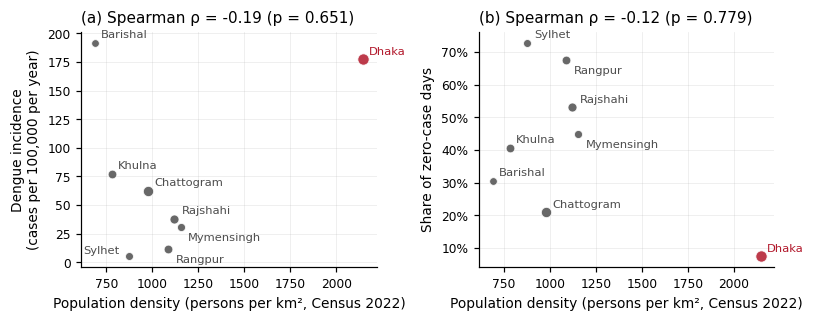

In [7]:
# label offsets (points) chosen so division names do not overlap
LABEL_OFF = {("incidence_per100k_per_year", "Rangpur"): (5, -9), ("incidence_per100k_per_year", "Sylhet"): (-6, 2),
             ("incidence_per100k_per_year", "Mymensingh"): (5, -9), ("incidence_per100k_per_year", "Rajshahi"): (5, 3),
             ("zero_share", "Rangpur"): (5, -9), ("zero_share", "Sylhet"): (5, 3),
             ("zero_share", "Rajshahi"): (5, 3), ("zero_share", "Mymensingh"): (5, -9)}
fig, ax = plt.subplots(1, 2, figsize=(FULL_W, 3.0))
for a, col, lab in [(ax[0], "incidence_per100k_per_year", "Dengue incidence\n(cases per 100,000 per year)"),
                    (ax[1], "zero_share", "Share of zero-case days")]:
    for _, r in U.iterrows():
        c = URBAN_C if r.division == "Dhaka" else REST_C
        a.scatter(r.density, r[col], s=18 + r.population / 1.2e6, color=c, alpha=.85, edgecolor="white", lw=.6, zorder=3)
        off = LABEL_OFF.get((col, r.division), (4, 3))
        a.annotate(r.division, (r.density, r[col]), xytext=off, textcoords="offset points", fontsize=7.5, color=c,
                   ha="right" if off[0] < 0 else "left")
    a.set_xlabel("Population density (persons per km², Census 2022)"); a.set_ylabel(lab); a.grid(alpha=.25, lw=.5)
    if col == "zero_share": a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
k1, k2 = grad["density_vs_incidence"], grad["density_vs_zero_share"]
ax[0].set_title(f"(a) Spearman ρ = {k1['rho']:.2f} (p = {k1['p']:.3f})", loc="left")
ax[1].set_title(f"(b) Spearman ρ = {k2['rho']:.2f} (p = {k2['p']:.3f})", loc="left")
fig.tight_layout(); savefig(fig, "Fig4_urban_gradient")

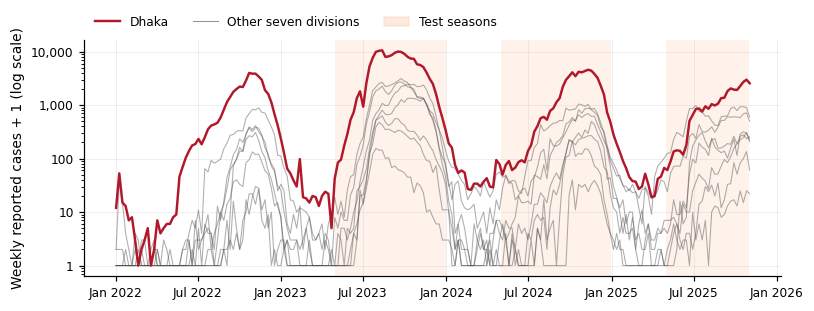

In [8]:
# Two transmission regimes over time: weekly cases (log scale), Dhaka vs. the other seven divisions
wk = df.set_index("date").groupby("division")["Patients"].resample("W-SUN").sum().unstack(0)
fig, ax = plt.subplots(figsize=(FULL_W, 2.9))
for d in DIVS:
    if d == "Dhaka": continue
    ax.plot(wk.index, wk[d] + 1, color=REST_C, lw=.7, alpha=.45)
ax.plot(wk.index, wk["Dhaka"] + 1, color=URBAN_C, lw=1.6, label="Dhaka")
ax.plot([], [], color=REST_C, lw=.7, alpha=.6, label="Other seven divisions")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_yscale("log"); ax.set_ylabel("Weekly reported cases + 1 (log scale)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
hl, ll = ax.get_legend_handles_labels()
hl.append(matplotlib.patches.Patch(color="#FDDBC7", alpha=.6)); ll.append("Test seasons")
ax.legend(hl, ll, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
for yr in [2023, 2024, 2025]:
    ax.axvspan(pd.Timestamp(f"{yr}-05-01"), pd.Timestamp(f"{yr}-12-31" if yr < 2025 else "2025-10-31"), color="#FDDBC7", alpha=.35, lw=0)
ax.grid(alpha=.25, lw=.5); fig.tight_layout(); savefig(fig, "Fig3_weekly_series_regimes")

### 2b. Dhaka city corporations vs. the rest of Dhaka Division
The daily DGHS bulletins split Dhaka Division into the Dhaka North and South City Corporations and the rest of the division.
We use the published annual totals (DGHS figures as reported in the press; sources in the manuscript, Table "city") and the
Census 2022 populations of the two city corporations. For 2022 and 2023 DGHS reported only the Dhaka city total, so the rest of
the division is the Dhaka total in this dataset minus the city total. Counts are assigned by hospital location.

In [9]:
POP_CITY = 5979537 + 4299345                                   # DNCC + DSCC, Census 2022
POP_DHAKA_DIV = int(COV.set_index("division").loc["Dhaka", "population"]) if "COV" in dir() else 44215107
POP_REST = POP_DHAKA_DIV - POP_CITY
dhaka_year = df[df.division == "Dhaka"].groupby(df.date.dt.year)["Patients"].sum()
CITY = pd.DataFrame([
    # year, period, city-corporation total, rest of division (None = derive from dataset), source
    (2022, "Full year",     39320,         None,  "DGHS via The Report, 1 Jan 2023"),
    (2023, "Full year",     110008,        None,  "DGHS via Hasan et al. (2025): 321,179 - 211,171"),
    (2024, "1 Jan-21 Dec",  21049 + 17667, 18482, "DGHS via Outbreak News Today, 21 Dec 2024"),
    (2025, "1 Jan-25 Nov",  14406 + 13060, 15640, "DGHS via Dhaka Tribune, 26 Nov 2025"),
], columns=["year", "period", "city", "rest", "source"])
CITY["rest_derived"] = CITY.rest.isna()
CITY["rest"] = [r if pd.notna(r) else int(dhaka_year[y] - c) for y, c, r in zip(CITY.year, CITY.city, CITY.rest)]
CITY["inc_city"] = CITY.city / POP_CITY * 1e5
CITY["inc_rest"] = CITY.rest / POP_REST * 1e5
CITY["ratio"] = CITY.inc_city / CITY.inc_rest
CITY["city_share"] = CITY.city / (CITY.city + CITY.rest)
print("2024 check: DGHS city + rest =", 21049 + 17667 + 18482, "| dataset Dhaka 2024 =", int(dhaka_year[2024]),
      f"| ratio = {(21049 + 17667 + 18482) / dhaka_year[2024]:.3f}")
CITY.to_csv(os.path.join(TAB, "T2b_dhaka_city_vs_rest.csv"), index=False)
R["dhaka_city_vs_rest"] = {"pop_city": POP_CITY, "pop_rest": POP_REST, "table": CITY.round(4).to_dict(orient="records")}
CITY.round(1)


2024 check: DGHS city + rest = 57198 | dataset Dhaka 2024 = 58536 | ratio = 0.977


,year,period,city,rest,source,rest_derived,inc_city,inc_rest,ratio,city_share
0,2022,Full year,39320,2946.0,"DGHS via The Report, 1 Jan 2023",True,382.5,8.7,44.1,0.9
1,2023,Full year,110008,58664.0,"DGHS via Hasan et al. (2025): 321,179 - 211,171",True,1070.2,172.9,6.2,0.7
2,2024,1 Jan-21 Dec,38716,18482.0,"DGHS via Outbreak News Today, 21 Dec 2024",False,376.7,54.5,6.9,0.7
3,2025,1 Jan-25 Nov,27466,15640.0,"DGHS via Dhaka Tribune, 26 Nov 2025",False,267.2,46.1,5.8,0.6


## 3. Season timing per division and year

In [10]:
def season_timing(s):
    # s: daily series for one division-year (calendar year). Onset/end = 10%/90% of cumulative annual cases; peak = max 7-day mean.
    tot = s.sum()
    if tot < 20: return pd.Series({"onset": np.nan, "peak": np.nan, "end": np.nan, "duration_days": np.nan, "annual_cases": tot})
    c = s.cumsum() / tot
    onset = int((c >= .10).values.argmax()); end = int((c >= .90).values.argmax())
    peak = int(s.rolling(7, center=True, min_periods=1).mean().values.argmax())
    return pd.Series({"onset": onset + 1, "peak": peak + 1, "end": end + 1, "duration_days": end - onset, "annual_cases": tot})

full = df[df.date.dt.year <= 2024]  # complete calendar years only (2025 ends in October)
TT = full.groupby(["division", full.date.dt.year])["Patients"].apply(lambda s: season_timing(s.reset_index(drop=True))).unstack()
TT.index.names = ["division", "year"]; TT = TT.reset_index()
TT.to_csv(os.path.join(TAB, "T3_season_timing.csv"), index=False)
piv = TT.pivot(index="division", columns="year", values="peak")
lag_vs_dhaka = TT.merge(TT[TT.division == "Dhaka"][["year", "onset", "peak"]].rename(columns={"onset": "dh_on", "peak": "dh_pk"}), on="year")
lag_vs_dhaka["onset_minus_dhaka"] = lag_vs_dhaka.onset - lag_vs_dhaka.dh_on
lag_vs_dhaka["peak_minus_dhaka"] = lag_vs_dhaka.peak - lag_vs_dhaka.dh_pk
summ = lag_vs_dhaka[lag_vs_dhaka.division != "Dhaka"].groupby("division")[["onset_minus_dhaka", "peak_minus_dhaka"]].mean()
R["season_timing"] = {"table": TT.round(1).to_dict(orient="records"),
                      "mean_onset_minus_dhaka_days": summ.onset_minus_dhaka.round(1).to_dict(),
                      "mean_peak_minus_dhaka_days": summ.peak_minus_dhaka.round(1).to_dict(),
                      "dhaka_duration_mean_days": float(TT[TT.division == "Dhaka"].duration_days.mean()),
                      "rest_duration_median_days": float(TT[TT.division != "Dhaka"].duration_days.median()),
                      "share_divisions_onset_after_dhaka": float((lag_vs_dhaka[lag_vs_dhaka.division != "Dhaka"].onset_minus_dhaka > 0).mean()),
                      "share_divisions_peak_after_dhaka": float((lag_vs_dhaka[lag_vs_dhaka.division != "Dhaka"].peak_minus_dhaka > 0).mean())}
print(summ.round(1)); TT.round(0)

            onset_minus_dhaka  peak_minus_dhaka
division                                       
Barishal                  5.7              14.3
Chattogram               -5.3              19.0
Khulna                   20.3              23.0
Mymensingh               14.3               1.0
Rajshahi                 28.0              27.3
Rangpur                  17.3             -10.7
Sylhet                   25.7               0.0


,division,year,onset,peak,end,duration_days,annual_cases
0,Barishal,2022,269,303,331,62,3103
1,Barishal,2023,207,266,312,105,37932
2,Barishal,2024,215,309,335,120,8829
3,Chattogram,2022,247,316,338,91,9106
4,Chattogram,2023,205,265,312,107,44686
5,Chattogram,2024,206,311,330,124,15564
6,Dhaka,2022,237,303,331,94,42266
7,Dhaka,2023,200,220,311,111,168672
8,Dhaka,2024,237,312,335,98,58536
9,Khulna,2022,263,309,330,67,3321


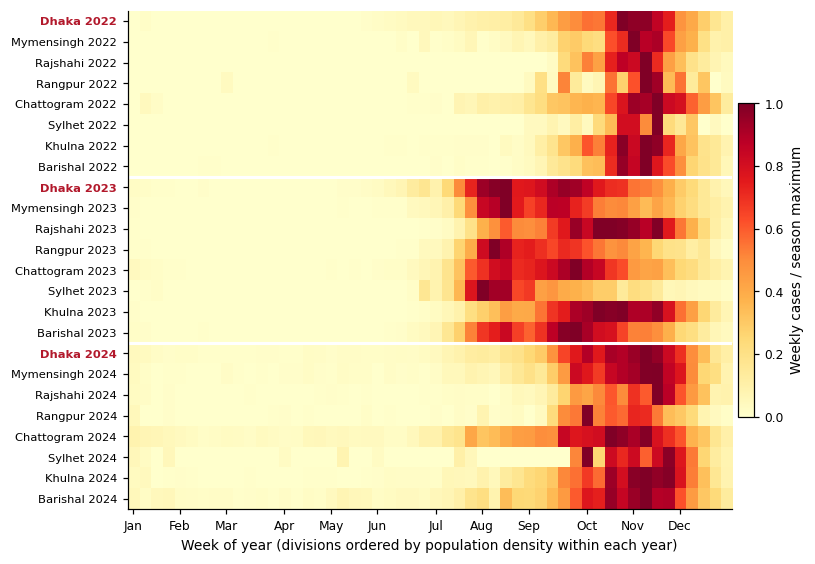

In [11]:
# Heat map: weekly cases normalised by each division-year's maximum
wk_n = wk[wk.index < "2025-01-01"].copy()
rows, labels = [], []
order = U.division.tolist()  # by density
for yr in [2022, 2023, 2024]:
    for d in order:
        s = wk_n[d][wk_n.index.year == yr]
        rows.append((s / s.max()).values[:52]); labels.append(f"{d} {yr}")
M = np.vstack([np.pad(r, (0, 52 - len(r)), constant_values=np.nan) for r in rows])
fig, ax = plt.subplots(figsize=(FULL_W, 5.2))
im = ax.imshow(M, aspect="auto", cmap="YlOrRd", interpolation="nearest")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7.5)
for i, l in enumerate(labels):
    if l.startswith("Dhaka"): ax.get_yticklabels()[i].set_color(URBAN_C); ax.get_yticklabels()[i].set_fontweight("bold")
mt = [pd.Timestamp(f"2023-{m:02d}-01").dayofyear // 7 for m in range(1, 13)]
ax.set_xticks(mt); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
for k in (8, 16): ax.axhline(k - .5, color="white", lw=2)
cb = fig.colorbar(im, ax=ax, fraction=.025, pad=.01); cb.set_label("Weekly cases / season maximum")
ax.set_xlabel("Week of year (divisions ordered by population density within each year)")
fig.tight_layout(); savefig(fig, "Fig5_season_timing_heatmap")

## 4. Spatial lead–lag: does Dhaka lead the other divisions?

In [12]:
# Cross-correlation of weekly log(1+cases); positive lag k means Dhaka at week t correlates with division at week t+k (Dhaka leads).
# We use first differences (week-to-week growth) to remove the shared seasonal level, then also report raw-level CCF.
def ccf(x, y, k):
    if k >= 0: a, b = x[:len(x) - k], y[k:]
    else: a, b = x[-k:], y[:len(y) + k]
    return np.corrcoef(a, b)[0, 1]
LAGS = range(-6, 7)
lw = np.log1p(wk[wk.index < "2025-10-27"])
CC = []
for d in DIVS:
    if d == "Dhaka": continue
    xd, yd = lw["Dhaka"].diff().dropna().values, lw[d].diff().dropna().values
    xl, yl = lw["Dhaka"].values, lw[d].values
    rd = {k: ccf(xd, yd, k) for k in LAGS}; rl = {k: ccf(xl, yl, k) for k in LAGS}
    kd = max(rd, key=rd.get); kl = max(rl, key=rl.get)
    CC.append({"division": d, "best_lag_growth_weeks": kd, "r_growth_at_best": rd[kd], "r_growth_lag0": rd[0],
               "best_lag_level_weeks": kl, "r_level_at_best": rl[kl], **{f"r_growth_lag{k}": rd[k] for k in LAGS}})
CC = pd.DataFrame(CC); CC.to_csv(os.path.join(TAB, "T4_dhaka_leadlag.csv"), index=False)
R["leadlag"] = {"table": CC.round(3).to_dict(orient="records"),
                "n_divisions_dhaka_leads_growth": int((CC.best_lag_growth_weeks > 0).sum()),
                "n_divisions_synchronous_growth": int((CC.best_lag_growth_weeks == 0).sum()),
                "median_best_lag_growth_weeks": float(CC.best_lag_growth_weeks.median()),
                "median_best_lag_level_weeks": float(CC.best_lag_level_weeks.median())}
print(CC[["division", "best_lag_growth_weeks", "r_growth_at_best", "r_growth_lag0", "best_lag_level_weeks", "r_level_at_best"]].round(2))

     division  best_lag_growth_weeks  r_growth_at_best  r_growth_lag0  \
0    Barishal                      0              0.39           0.39   
1  Chattogram                      0              0.45           0.45   
2      Khulna                      2              0.36           0.24   
3  Mymensingh                     -1              0.27           0.22   
4    Rajshahi                      0              0.28           0.28   
5     Rangpur                     -2              0.18           0.17   
6      Sylhet                      2              0.15           0.14   

   best_lag_level_weeks  r_level_at_best  
0                     0             0.86  
1                     0             0.94  
2                     1             0.93  
3                     1             0.93  
4                     2             0.88  
5                     1             0.84  
6                     1             0.79  


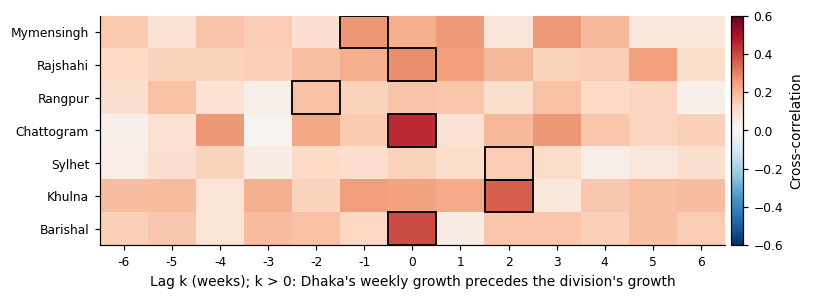

In [13]:
fig, ax = plt.subplots(figsize=(FULL_W, 2.8))
cols = [f"r_growth_lag{k}" for k in LAGS]
Mx = CC.set_index("division").loc[[d for d in U.division if d != "Dhaka"], cols].values
im = ax.imshow(Mx, aspect="auto", cmap="RdBu_r", vmin=-.6, vmax=.6)
ax.set_xticks(range(len(cols))); ax.set_xticklabels([str(k) for k in LAGS])
ax.set_yticks(range(Mx.shape[0])); ax.set_yticklabels([d for d in U.division if d != "Dhaka"])
for i in range(Mx.shape[0]):
    j = int(np.nanargmax(Mx[i])); ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="black", lw=1.2))
ax.set_xlabel("Lag k (weeks); k > 0: Dhaka's weekly growth precedes the division's growth")
cb = fig.colorbar(im, ax=ax, fraction=.03, pad=.01); cb.set_label("Cross-correlation")
fig.tight_layout(); savefig(fig, "Fig6_dhaka_leadlag")

## 5. Lagged climate–dengue associations by division

In [14]:
# Weekly aggregates. Spearman correlation between weather in week t-L and log(1+cases) in week t, L = 0..16 weeks.
W = df.set_index("date").groupby("division").resample("W-SUN").agg(
    {"Patients": "sum", "tmax": "mean", "tmin": "mean", "rainfall": "sum", "humidity": "mean"})
W = W.reset_index(); W = W[W.date < "2025-10-27"]
VARS = {"tmin": "Minimum temperature", "tmax": "Maximum temperature", "rainfall": "Rainfall (weekly total)", "humidity": "Relative humidity"}
CL = []
for d in DIVS:
    s = W[W.division == d].sort_values("date")
    yv = np.log1p(s.Patients.values)
    for v in VARS:
        for L in range(0, 17):
            x = s[v].shift(L).values
            m = ~np.isnan(x)
            r, p = stats.spearmanr(x[m], yv[m])
            CL.append({"division": d, "var": v, "lag_weeks": L, "rho": r, "p": p})
CL = pd.DataFrame(CL); CL.to_csv(os.path.join(TAB, "T5_climate_lag_correlations.csv"), index=False)
best = CL.loc[CL.groupby(["division", "var"]).rho.apply(lambda s: s.abs().idxmax())]
R["climate_lag"] = {"best_lag_by_division_var": best.round(3).to_dict(orient="records"),
                    "median_best_lag_weeks_by_var": best.groupby("var").lag_weeks.median().to_dict(),
                    "dhaka_best": best[best.division == "Dhaka"].round(3).to_dict(orient="records"),
                    "median_abs_best_rho_dhaka": float(best[best.division == "Dhaka"].rho.abs().median()),
                    "median_abs_best_rho_rest": float(best[best.division != "Dhaka"].rho.abs().median())}
print(best.pivot(index="division", columns="var", values="lag_weeks"))
print(best.pivot(index="division", columns="var", values="rho").round(2))

var         humidity  rainfall  tmax  tmin
division                                  
Barishal           6         9    16    11
Chattogram         8        10    16    12
Dhaka              5         9    13    11
Khulna             8        10    15    13
Mymensingh         6        11    13    10
Rajshahi           7        11    16    13
Rangpur            5        11    13    10
Sylhet            13        13     9     9
var         humidity  rainfall  tmax  tmin
division                                  
Barishal        0.68      0.59  0.45  0.65
Chattogram      0.71      0.72  0.52  0.79
Dhaka           0.59      0.72  0.70  0.86
Khulna          0.65      0.69  0.63  0.78
Mymensingh      0.53      0.67  0.69  0.83
Rajshahi        0.57      0.63  0.64  0.77
Rangpur         0.47      0.61  0.68  0.78
Sylhet          0.42      0.55  0.60  0.69


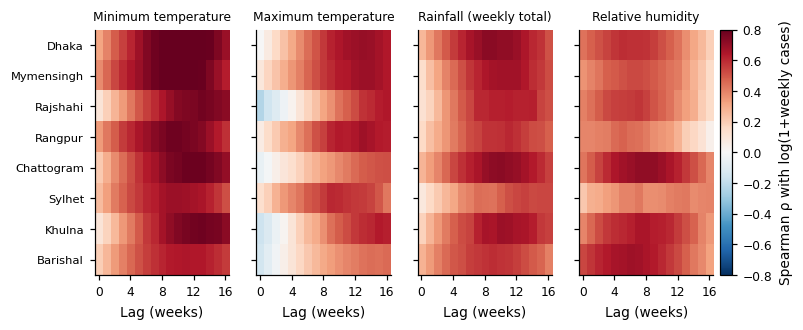

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(FULL_W, 2.9), sharey=True)
order = U.division.tolist()
for a, (v, lab) in zip(axs, VARS.items()):
    P = CL[CL["var"] == v].pivot(index="division", columns="lag_weeks", values="rho").loc[order]
    im = a.imshow(P.values, aspect="auto", cmap="RdBu_r", vmin=-.8, vmax=.8)
    a.set_title(lab, fontsize=8); a.set_xticks([0, 4, 8, 12, 16]); a.set_xlabel("Lag (weeks)")
    a.set_yticks(range(len(order))); a.set_yticklabels(order, fontsize=7.5)
cb = fig.colorbar(im, ax=axs, fraction=.02, pad=.01); cb.set_label("Spearman ρ with log(1+weekly cases)")
savefig(fig, "Fig7_climate_lag_heatmap")

## 6. Season-ahead, multi-horizon forecasting

**Design.** Direct forecasting of the daily count on target day *d* using only information available on the issue day *d − h*,
for horizons **h = 1, 7, 14 days**. Three *season-ahead* folds mimic deployment: each model is trained on everything before
1 May of the season year and tested on the following transmission season:

| Fold | Train | Test season |
|---|---|---|
| S2023 | ≤ 30 Apr 2023 | 1 May – 31 Dec 2023 (record outbreak) |
| S2024 | ≤ 30 Apr 2024 | 1 May – 31 Dec 2024 |
| S2025 (prospective hold-out) | ≤ 30 Apr 2025 | 1 May – 31 Oct 2025 |

Hyper-parameters are fixed in advance; nothing is tuned on a test season.
Weather enters only as *past* observations up to the issue day (no weather forecasts are assumed).

**Model families**
* Baselines: **persistence** (ŷ = count on the issue day) and **7-day moving average** on the issue day.
* **Level models** (predict the count itself): Random Forest, XGBoost-Tweedie,
  LightGBM-Tweedie, two-stage hurdle — all with history + weather + calendar + division features.
* **Level-anchored models**: LightGBM predicts the log growth ratio
  *z = log(1 + y_d) − log(1 + 7-day mean on the issue day)* and the forecast is *ŷ = exp(anchor + ẑ) − 1*.
  Because the forecast scales with the current level, it is not capped by the largest count seen in training.
  The **proposed model is declared before evaluation as the anchored LightGBM with case-history features only**;
  the anchored model with weather + calendar is reported as an ablation.

> Transparency note: the anchored formulation was introduced after a first run showed that level models cannot exceed
> training-range magnitudes in the record 2023 season (Section 6.1). All three seasons had been inspected at that point,
> so model-family comparisons are exploratory rather than pre-registered.

In [16]:
HORIZONS = [1, 7, 14]
SEASONS = {"S2023": ("2023-05-01", "2023-12-31"), "S2024": ("2024-05-01", "2024-12-31"), "S2025": ("2025-05-01", "2025-10-31")}

def make_features(h):
    d = df.copy()
    d["division_code"] = d.division.map({k: i for i, k in enumerate(DIVS)})
    d = d.merge(COV[["division", "density", "population"]], on="division", how="left")
    d["log_density"] = np.log(d.density); d["log_population"] = np.log(d.population)
    gb = d.groupby("division")
    yh = gb["Patients"].shift(h)                                    # count on the issue day
    d["c_last"] = yh
    d["c_lag7"] = gb["Patients"].shift(h + 7)
    for w in (7, 14, 28):
        d[f"c_roll{w}"] = yh.groupby(d.division).transform(lambda s: s.rolling(w).mean())
    d["c_growth"] = np.log1p(d.c_roll7) - np.log1p(d.groupby("division")["c_roll7"].shift(7))
    for v in ("tmax", "tmin", "humidity", "rainfall"):
        vh = gb[v].shift(h)
        for w in (7, 28):
            agg = "sum" if v == "rainfall" else "mean"
            d[f"{v}_r{w}"] = vh.groupby(d.division).transform(lambda s: s.rolling(w).agg(agg))
    for v in ("rainfall", "tmin", "humidity"):                     # lagged window 29-56 days before the issue day
        vh = gb[v].shift(h + 28)
        agg = "sum" if v == "rainfall" else "mean"
        d[f"{v}_r28_lag28"] = vh.groupby(d.division).transform(lambda s: s.rolling(28).agg(agg))
    d["month"] = d.date.dt.month
    d["doy_sin"] = np.sin(2 * np.pi * d.date.dt.dayofyear / 365.25); d["doy_cos"] = np.cos(2 * np.pi * d.date.dt.dayofyear / 365.25)
    # level-anchored representation
    d["anchor"] = np.log1p(d.c_roll7)
    d["r_last"] = np.log1p(d.c_last) - d.anchor; d["r_lag7"] = np.log1p(d.c_lag7) - d.anchor
    d["r_14"] = np.log1p(d.c_roll14) - d.anchor; d["r_28"] = np.log1p(d.c_roll28) - d.anchor
    d["z"] = np.log1p(d.Patients) - d.anchor
    return d.dropna(subset=["c_roll28", "c_growth", "rainfall_r28_lag28", "r_lag7"]).reset_index(drop=True)

FG = {
    "history":     ["c_last", "c_lag7", "c_roll7", "c_roll14", "c_roll28", "c_growth"],
    "history_rel": ["anchor", "r_last", "r_lag7", "r_14", "r_28", "c_growth"],
    "weather":     ["tmax_r7", "tmax_r28", "tmin_r7", "tmin_r28", "humidity_r7", "humidity_r28", "rainfall_r7", "rainfall_r28",
                    "rainfall_r28_lag28", "tmin_r28_lag28", "humidity_r28_lag28"],
    "calendar":    ["month", "doy_sin", "doy_cos"],
    "division":    ["division_code"],
    "urban":       ["log_density", "log_population"],
}
FULL = FG["history"] + FG["weather"] + FG["calendar"] + FG["division"]
ANCH_HIST = FG["history_rel"] + FG["division"]
ANCH_FULL = FG["history_rel"] + FG["weather"] + FG["calendar"] + FG["division"]
FEATS = {h: make_features(h) for h in HORIZONS}
print({h: len(v) for h, v in FEATS.items()})

{1: 10752, 7: 10704, 14: 10648}


In [17]:
def lgb(**kw):
    return LGBMRegressor(n_estimators=200, max_depth=6, learning_rate=.05, random_state=RNG, verbosity=-1, **kw)

def fit_predict(name, tr, te, cols=None):
    # Returns non-negative count forecasts for the rows of `te`.
    if name.startswith("Anchored"):
        m = lgb().fit(tr[cols], tr.z)
        return np.clip(np.expm1(te.anchor.values + m.predict(te[cols])), 0, None)
    cols = cols or FULL
    Xtr, ytr, Xte = tr[cols], tr.Patients, te[cols]
    if name == "Random Forest":
        m = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=RNG, n_jobs=-1)
    elif name == "XGBoost-Tweedie":
        m = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=.05, random_state=RNG, n_jobs=-1,
                         objective="reg:tweedie", tweedie_variance_power=1.3)
    elif name == "LightGBM-Tweedie":
        m = lgb(objective="tweedie", tweedie_variance_power=1.3)
    elif name == "Hurdle (2-stage)":
        clf = LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=.05, random_state=RNG, verbosity=-1).fit(Xtr, (ytr > 0).astype(int))
        pos = (ytr > 0).values
        reg = lgb().fit(Xtr[pos], np.log1p(ytr[pos]))
        return clf.predict_proba(Xte)[:, 1] * np.clip(np.expm1(reg.predict(Xte)), 0, None)
    else:
        raise ValueError(name)
    return np.clip(m.fit(Xtr, ytr).predict(Xte), 0, None)

LEVEL = ["Random Forest", "XGBoost-Tweedie", "LightGBM-Tweedie", "Hurdle (2-stage)"]
ANCHORED = {"Anchored LightGBM (history)": ANCH_HIST, "Anchored LightGBM (history + weather + calendar)": ANCH_FULL}
PROPOSED = "Anchored LightGBM (history)"
ORDER_M = ["Persistence", "Moving average (7 d)"] + LEVEL + list(ANCHORED)

PRED = []
t0 = time.time()
for h in HORIZONS:
    D = FEATS[h]
    for s, (a, b) in SEASONS.items():
        tr = D[D.date < a]; te = D[(D.date >= a) & (D.date <= b)]
        base = te[["date", "division", "Patients"]].assign(h=h, season=s)
        PRED.append(base.assign(model="Persistence", pred=te.c_last.values))
        PRED.append(base.assign(model="Moving average (7 d)", pred=te.c_roll7.values))
        for mname in LEVEL:
            PRED.append(base.assign(model=mname, pred=fit_predict(mname, tr, te)))
        for mname, cols in ANCHORED.items():
            PRED.append(base.assign(model=mname, pred=fit_predict(mname, tr, te, cols)))
    print(f"h={h} done ({time.time() - t0:.0f}s)")
PRED = pd.concat(PRED, ignore_index=True)
PRED["err"] = PRED.pred - PRED.Patients; PRED["ae"] = PRED.err.abs()
thr = PRED[PRED.model == "Persistence"].groupby(["season", "h"]).Patients.quantile(.9).rename("ob_thr")
PRED = PRED.merge(thr, left_on=["season", "h"], right_index=True); PRED["ob"] = PRED.Patients >= PRED.ob_thr
PRED.to_csv(os.path.join(RES, "season_ahead_predictions.csv.gz"), index=False)
print(PRED.groupby(["season", "h"]).size().unstack() // len(ORDER_M))

h=1 done (22s)
h=7 done (42s)
h=14 done (62s)
h         1     7     14
season                  
S2023   1960  1960  1960
S2024   1960  1960  1960
S2025   1472  1472  1472


In [18]:
def summarise(P):
    gq = P.groupby(["h", "model", "season"])
    t = pd.DataFrame({"MAE": gq.ae.mean(), "RMSE": gq.err.apply(lambda e: np.sqrt((e ** 2).mean())),
                      "bias": gq.err.mean(), "MAE_outbreak": P[P.ob].groupby(["h", "model", "season"]).ae.mean()}).reset_index()
    pers = t[t.model == "Persistence"][["h", "season", "MAE"]].rename(columns={"MAE": "MAE_pers"})
    t = t.merge(pers, on=["h", "season"]); t["skill_vs_persistence"] = 1 - t.MAE / t.MAE_pers
    return t
S = summarise(PRED)
S.to_csv(os.path.join(TAB, "T7_season_ahead_by_season.csv"), index=False)
Smean = S.groupby(["h", "model"])[["MAE", "RMSE", "MAE_outbreak", "skill_vs_persistence"]].mean().reset_index()
Smean.to_csv(os.path.join(TAB, "T7_season_ahead_mean_over_seasons.csv"), index=False)
R["season_ahead"] = {"by_season": S.round(4).to_dict(orient="records"), "mean": Smean.round(4).to_dict(orient="records"),
                     "test_rows_per_model": (PRED[PRED.model == "Persistence"].groupby(["season", "h"]).size()).astype(int).reset_index().to_dict(orient="records"),
                     "outbreak_thresholds": thr.round(1).reset_index().to_dict(orient="records"), "proposed_model": PROPOSED}
tab = S.pivot_table(index=["h", "model"], columns="season", values="MAE").reindex(ORDER_M, level=1).round(2)
tab

season                                                S2023  S2024  S2025
h  model                                                                 
1  Persistence                                        31.69  19.59  16.97
   Moving average (7 d)                               29.82  15.33  15.23
   Random Forest                                      92.29  15.94  15.78
   XGBoost-Tweedie                                    92.36  16.93  16.10
   LightGBM-Tweedie                                   83.76  16.04  15.93
   Hurdle (2-stage)                                   80.59  16.04  15.67
   Anchored LightGBM (history)                        36.04  15.49  15.65
   Anchored LightGBM (history + weather + calendar)   50.99  16.48  15.91
7  Persistence                                        33.64  15.69  14.23
   Moving average (7 d)                               43.70  19.48  16.60
   Random Forest                                      64.56  15.79  17.85
   XGBoost-Tweedie                                    65.94  14.56  16.56
   LightGBM-Tweedie                                   66.67  14.04  17.94
   Hurdle (2-stage)                                   65.08  13.92  16.08
   Anchored LightGBM (history)                        38.22  13.61  14.09
   Anchored LightGBM (history + weather + calendar)   81.83  14.29  15.41
14 Persistence                                        52.81  20.50  16.03
   Moving average (7 d)                               61.44  24.51  18.54
   Random Forest                                      83.62  20.29  21.32
   XGBoost-Tweedie                                    83.55  17.51  19.84
   LightGBM-Tweedie                                   78.72  18.16  19.93
   Hurdle (2-stage)                                   79.17  17.61  18.92
   Anchored LightGBM (history)                        60.01  17.31  16.55
   Anchored LightGBM (history + weather + calendar)  133.67  17.34  18.62

In [19]:
# Prospective 2025 hold-out, with R2
from sklearn.metrics import r2_score
P25 = PRED[PRED.season == "S2025"]
T25 = P25.groupby(["h", "model"]).apply(lambda x: pd.Series({
        "MAE": x.ae.mean(), "RMSE": np.sqrt((x.err ** 2).mean()), "R2": r2_score(x.Patients, x.pred),
        "MAE_outbreak": x[x.ob].ae.mean()})).reset_index()
T25 = T25.merge(T25[T25.model == "Persistence"][["h", "MAE"]].rename(columns={"MAE": "MAE_p"}), on="h")
T25["skill"] = 1 - T25.MAE / T25.MAE_p; T25 = T25.drop(columns="MAE_p")
T25.to_csv(os.path.join(TAB, "T7b_prospective_2025.csv"), index=False)
R["prospective_2025"] = T25.round(4).to_dict(orient="records")
T25.set_index(["h", "model"]).reindex(ORDER_M, level=1).round(3)

MAE    RMSE     R2  \
h  model                                                                     
1  Persistence                                       16.975  34.067  0.805   
   Moving average (7 d)                              15.225  29.154  0.857   
   Random Forest                                     15.776  30.301  0.846   
   XGBoost-Tweedie                                   16.103  31.928  0.829   
   LightGBM-Tweedie                                  15.929  31.214  0.836   
   Hurdle (2-stage)                                  15.670  30.283  0.846   
   Anchored LightGBM (history)                       15.646  29.588  0.853   
   Anchored LightGBM (history + weather + calendar)  15.913  30.750  0.841   
7  Persistence                                       14.232  26.792  0.879   
   Moving average (7 d)                              16.601  31.633  0.832   
   Random Forest                                     17.854  32.661  0.821   
   XGBoost-Tweedie                                   16.564  31.348  0.835   
   LightGBM-Tweedie                                  17.938  33.926  0.807   
   Hurdle (2-stage)                                  16.084  29.392  0.855   
   Anchored LightGBM (history)                       14.094  26.861  0.879   
   Anchored LightGBM (history + weather + calendar)  15.407  29.059  0.858   
14 Persistence                                       16.033  31.121  0.837   
   Moving average (7 d)                              18.543  35.977  0.783   
   Random Forest                                     21.324  37.795  0.760   
   XGBoost-Tweedie                                   19.843  36.111  0.781   
   LightGBM-Tweedie                                  19.928  35.940  0.783   
   Hurdle (2-stage)                                  18.923  35.055  0.794   
   Anchored LightGBM (history)                       16.548  30.789  0.841   
   Anchored LightGBM (history + weather + calendar)  18.620  35.751  0.785   

                                                     MAE_outbreak  skill  
h  model                                                                  
1  Persistence                                             54.554  0.000  
   Moving average (7 d)                                    49.587  0.103  
   Random Forest                                           47.989  0.071  
   XGBoost-Tweedie                                         50.990  0.051  
   LightGBM-Tweedie                                        47.012  0.062  
   Hurdle (2-stage)                                        50.221  0.077  
   Anchored LightGBM (history)                             52.019  0.078  
   Anchored LightGBM (history + weather + calendar)        53.397  0.063  
7  Persistence                                             46.000  0.000  
   Moving average (7 d)                                    59.314 -0.166  
   Random Forest                                           55.236 -0.255  
   XGBoost-Tweedie                                         49.763 -0.164  
   LightGBM-Tweedie                                        54.296 -0.260  
   Hurdle (2-stage)                                        49.377 -0.130  
   Anchored LightGBM (history)                             46.441  0.010  
   Anchored LightGBM (history + weather + calendar)        49.402 -0.083  
14 Persistence                                             58.507  0.000  
   Moving average (7 d)                                    72.507 -0.157  
   Random Forest                                           55.804 -0.330  
   XGBoost-Tweedie                                         60.971 -0.238  
   LightGBM-Tweedie                                        59.429 -0.243  
   Hurdle (2-stage)                                        59.035 -0.180  
   Anchored LightGBM (history)                             57.434 -0.032  
   Anchored LightGBM (history + weather + calendar)        57.090 -0.161

### 6.1 Why level models fail in a record season: the extrapolation ceiling
Tree ensembles predict averages of training targets, so they cannot forecast counts above the training range.
We compare the training maximum with the test-season maximum in Dhaka and plot the 2023 forecasts.

In [20]:
EX = []
for s, (a, b) in SEASONS.items():
    tr = df[(df.date < a) & (df.division == "Dhaka")]; te = df[(df.date >= a) & (df.date <= b) & (df.division == "Dhaka")]
    pk = te.Patients.rolling(7, center=True, min_periods=1).mean()
    EX.append({"season": s, "dhaka_train_max": int(tr.Patients.max()), "dhaka_test_max": int(te.Patients.max()),
               "ratio_test_to_train_max": te.Patients.max() / tr.Patients.max(),
               "dhaka_test_days_above_train_max": int((te.Patients > tr.Patients.max()).sum()),
               "dhaka_peak_date": str(te.date.iloc[int(pk.values.argmax())].date())})
EX = pd.DataFrame(EX)
for s in SEASONS:
    for m in ORDER_M:
        q = PRED[(PRED.season == s) & (PRED.h == 7) & (PRED.model == m) & (PRED.division == "Dhaka")]
        EX.loc[EX.season == s, f"max_pred_h7__{m}"] = q.pred.max()
EX.to_csv(os.path.join(TAB, "T7c_extrapolation_diagnostic.csv"), index=False)
R["extrapolation"] = EX.round(2).to_dict(orient="records")
R["dhaka_peak_doy_by_year"] = TT[TT.division == "Dhaka"].set_index("year").peak.to_dict()
EX.T

,0,1,2
season,S2023,S2024,S2025
dhaka_train_max,749,1703,1703
dhaka_test_max,1703,875,600
ratio_test_to_train_max,2.273698,0.513799,0.352319
dhaka_test_days_above_train_max,114,0,0
dhaka_peak_date,2023-08-08,2024-11-07,2025-10-29
max_pred_h7__Persistence,1703.0,875.0,520.0
max_pred_h7__Moving average (7 d),1519.571429,655.857143,401.142857
max_pred_h7__Random Forest,624.475,952.12,628.452968
max_pred_h7__XGBoost-Tweedie,639.230225,880.162048,601.751282


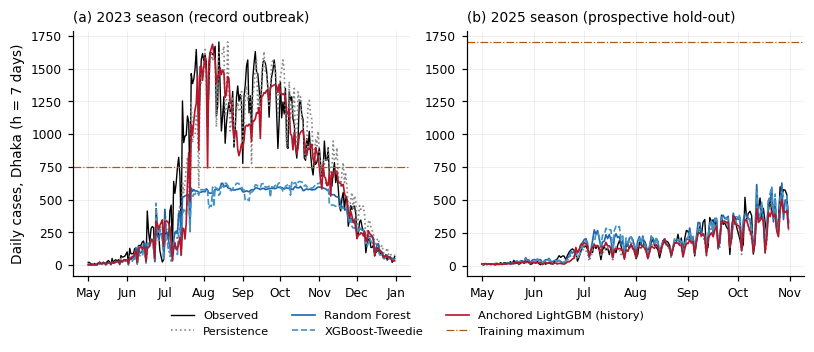

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(FULL_W, 2.9), sharey=False)
for a, (s, ttl) in zip(axs, [("S2023", "(a) 2023 season (record outbreak)"), ("S2025", "(b) 2025 season (prospective hold-out)")]):
    ob = PRED[(PRED.season == s) & (PRED.h == 7) & (PRED.division == "Dhaka") & (PRED.model == "Persistence")].sort_values("date")
    a.plot(ob.date, ob.Patients, color="black", lw=.9, label="Observed")
    for m, c, ls in [("Persistence", "#888888", ":"), ("Random Forest", "#2166AC", "-"), ("XGBoost-Tweedie", "#4393C3", "--"),
                     (PROPOSED, URBAN_C, "-")]:
        q = PRED[(PRED.season == s) & (PRED.h == 7) & (PRED.division == "Dhaka") & (PRED.model == m)].sort_values("date")
        a.plot(q.date, q.pred, color=c, lw=1.1, ls=ls, label=m)
    trmax = EX.set_index("season").loc[s, "dhaka_train_max"]
    a.axhline(trmax, color="#B35806", lw=.8, ls="-.", label="Training maximum")
    a.set_title(ttl, loc="left", fontsize=9); a.grid(alpha=.25, lw=.5)
    a.xaxis.set_major_locator(mdates.MonthLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axs[0].set_ylabel("Daily cases, Dhaka (h = 7 days)")
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False, fontsize=7.5, bbox_to_anchor=(.5, -.1))
fig.tight_layout(); savefig(fig, "Fig9_dhaka_extrapolation")

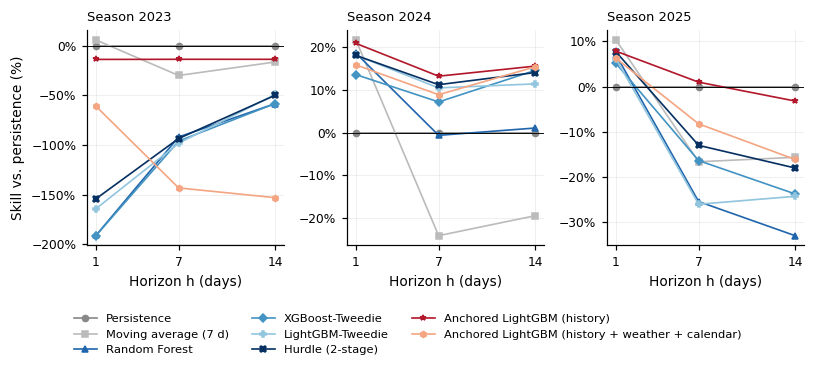

In [22]:
mk_ = dict(zip(ORDER_M, ["o", "s", "^", "D", "P", "X", "*", "h"]))
colr = {"Persistence": "#888888", "Moving average (7 d)": "#BBBBBB", "Random Forest": "#2166AC", "XGBoost-Tweedie": "#4393C3",
        "LightGBM-Tweedie": "#92C5DE", "Hurdle (2-stage)": "#053061", PROPOSED: URBAN_C,
        "Anchored LightGBM (history + weather + calendar)": "#F4A582"}
fig, axs = plt.subplots(1, 3, figsize=(FULL_W, 2.8), sharex=True)
for a, s in zip(axs, SEASONS):  # linear axes per panel
    for m in ORDER_M:
        q = S[(S.season == s) & (S.model == m)].sort_values("h")
        a.plot(q.h, q.skill_vs_persistence * 100, marker=mk_[m], color=colr[m], lw=1.1, ms=4, label=m)
    a.axhline(0, color="black", lw=.6); a.set_xticks(HORIZONS); a.set_title(s.replace("S", "Season "), fontsize=8.5, loc="left")
    a.set_xlabel("Horizon h (days)"); a.grid(alpha=.25, lw=.5)
    a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(100, decimals=0))
axs[0].set_ylabel("Skill vs. persistence (%)")
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False, fontsize=7.5, bbox_to_anchor=(.5, -.2))
fig.tight_layout(); savefig(fig, "Fig8_skill_by_season_horizon")

## 7. Skill by division (urban core vs. the rest) and moving-block bootstrap CIs

In [23]:
def block_boot_diff(P, m_a, m_b, B=2000, block=14, seed=RNG):
    # Mean daily MAE difference (m_a - m_b), all divisions of a day kept together; moving-block bootstrap over days.
    A = P[P.model == m_a].set_index(["date", "division"]).ae; Bv = P[P.model == m_b].set_index(["date", "division"]).ae
    day = (A - Bv).groupby(level=0).mean().sort_index().values
    rng = np.random.default_rng(seed); nd = len(day); nb = int(np.ceil(nd / block)); bs = []
    for _ in range(B):
        st = rng.integers(0, nd - block + 1, nb); bs.append(np.concatenate([day[i:i + block] for i in st])[:nd].mean())
    return float(day.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

CI = []
for h in HORIZONS:
    for s in SEASONS:
        P = PRED[(PRED.h == h) & (PRED.season == s)]
        best_level = S[(S.h == h) & (S.season == s) & (S.model.isin(LEVEL))].sort_values("MAE").model.iloc[0]
        for ref in ["Persistence", best_level]:
            m, lo, hi = block_boot_diff(P, PROPOSED, ref)
            CI.append({"h": h, "season": s, "comparison": f"{PROPOSED} - {ref}", "ref": ref,
                       "mae_diff": m, "ci_lo": lo, "ci_hi": hi, "significant": (hi < 0) or (lo > 0)})
CI = pd.DataFrame(CI); CI.to_csv(os.path.join(TAB, "T8b_bootstrap_ci.csv"), index=False)
R["bootstrap_ci"] = CI.round(3).to_dict(orient="records")

DIVSK = []
for h in HORIZONS:
    for s in SEASONS:
        P = PRED[(PRED.h == h) & (PRED.season == s)]
        for d in DIVS:
            q = P[P.division == d].groupby("model").ae.mean()
            DIVSK.append({"h": h, "season": s, "division": d, "MAE_proposed": q[PROPOSED], "MAE_pers": q["Persistence"],
                          "MAE_RF": q["Random Forest"], "mean_cases": P[(P.division == d) & (P.model == PROPOSED)].Patients.mean()})
DIVSK = pd.DataFrame(DIVSK)
DIVSK["skill_proposed"] = 1 - DIVSK.MAE_proposed / DIVSK.MAE_pers
DIVSK["skill_RF"] = 1 - DIVSK.MAE_RF / DIVSK.MAE_pers
DIVSK.to_csv(os.path.join(TAB, "T8_division_skill.csv"), index=False)
# pooled-over-seasons skill per division (ratio of summed MAEs, robust to tiny-MAE divisions)
DS = DIVSK.groupby(["h", "division"]).apply(lambda x: pd.Series({
        "skill_proposed": 1 - x.MAE_proposed.sum() / x.MAE_pers.sum(), "skill_RF": 1 - x.MAE_RF.sum() / x.MAE_pers.sum(),
        "MAE_proposed": x.MAE_proposed.mean(), "MAE_pers": x.MAE_pers.mean(), "mean_cases": x.mean_cases.mean()})).reset_index()
R["division_skill"] = DS.round(4).to_dict(orient="records")
R["division_skill_dhaka_vs_rest"] = {int(h): {"dhaka_proposed": float(DS[(DS.h == h) & (DS.division == "Dhaka")].skill_proposed.iloc[0]),
                                              "rest_median_proposed": float(DS[(DS.h == h) & (DS.division != "Dhaka")].skill_proposed.median()),
                                              "dhaka_RF": float(DS[(DS.h == h) & (DS.division == "Dhaka")].skill_RF.iloc[0]),
                                              "rest_median_RF": float(DS[(DS.h == h) & (DS.division != "Dhaka")].skill_RF.median())}
                                     for h in HORIZONS}
print(CI.round(2).to_string())
DS.pivot(index="division", columns="h", values=["skill_proposed", "skill_RF"]).reindex(U.division).round(3)

     h season                                      comparison               ref  mae_diff  ci_lo  ci_hi  significant
0    1  S2023       Anchored LightGBM (history) - Persistence       Persistence      4.35   1.61   7.97         True
1    1  S2023  Anchored LightGBM (history) - Hurdle (2-stage)  Hurdle (2-stage)    -44.54 -68.50 -27.00         True
2    1  S2024       Anchored LightGBM (history) - Persistence       Persistence     -4.10  -5.95  -2.63         True
3    1  S2024     Anchored LightGBM (history) - Random Forest     Random Forest     -0.45  -1.20   0.27        False
4    1  S2025       Anchored LightGBM (history) - Persistence       Persistence     -1.33  -2.61  -0.18         True
5    1  S2025  Anchored LightGBM (history) - Hurdle (2-stage)  Hurdle (2-stage)     -0.02  -0.64   0.59        False
6    7  S2023       Anchored LightGBM (history) - Persistence       Persistence      4.58  -0.58  10.72        False
7    7  S2023     Anchored LightGBM (history) - Random Forest   

skill_proposed               skill_RF              
h                      1      7      14       1      7      14
division                                                      
Dhaka              -0.028 -0.020 -0.070   -1.298 -0.975 -0.523
Mymensingh          0.128  0.002 -0.127    0.056 -0.247 -0.430
Rajshahi            0.086  0.021 -0.138   -0.296 -0.234 -0.295
Rangpur             0.023  0.007 -0.151    0.071 -0.217 -0.477
Chattogram         -0.024 -0.039 -0.001   -0.495 -0.174 -0.272
Sylhet              0.083  0.146  0.076   -0.222 -0.359 -0.637
Khulna              0.077  0.014  0.135   -0.683 -0.012 -0.078
Barishal            0.066 -0.191 -0.093   -0.583 -0.383 -0.374

## 8. Feature-group ablation in both formulations (does weather help, and do Census covariates replace division identity?)

In [24]:
ABL = {
  "level":    {"History": FG["history"] + FG["division"],
               "History + weather": FG["history"] + FG["weather"] + FG["division"],
               "History + calendar": FG["history"] + FG["calendar"] + FG["division"],
               "History + weather + calendar": FULL,
               "Census covariates instead of division ID": FG["history"] + FG["weather"] + FG["calendar"] + FG["urban"],
               "Weather + calendar (no case history)": FG["weather"] + FG["calendar"] + FG["division"]},
  "anchored": {"History": ANCH_HIST,
               "History + weather": FG["history_rel"] + FG["weather"] + FG["division"],
               "History + calendar": FG["history_rel"] + FG["calendar"] + FG["division"],
               "History + weather + calendar": ANCH_FULL,
               "Census covariates instead of division ID": FG["history_rel"] + FG["weather"] + FG["calendar"] + FG["urban"]},
}
AB = []
for h in HORIZONS:
    D = FEATS[h]
    for s, (a, b) in SEASONS.items():
        tr = D[D.date < a]; te = D[(D.date >= a) & (D.date <= b)]
        for form, sets in ABL.items():
            for nm, cols in sets.items():
                p = fit_predict("Anchored" if form == "anchored" else "LightGBM-Tweedie", tr, te, cols)
                e = np.abs(te.Patients.values - p)
                AB.append({"h": h, "season": s, "formulation": form, "feature_set": nm, "MAE": e.mean(),
                           "MAE_dhaka": e[te.division.values == "Dhaka"].mean(), "MAE_rest": e[te.division.values != "Dhaka"].mean()})
AB = pd.DataFrame(AB); AB.to_csv(os.path.join(TAB, "T9_ablation.csv"), index=False)
R["ablation"] = {"level_model": "LightGBM-Tweedie", "anchored_model": "LightGBM on log growth ratio",
                 "rows": AB.round(3).to_dict(orient="records")}
AB.pivot_table(index=["formulation", "feature_set"], columns=["h", "season"], values="MAE").round(1)

h                                                        1               \
season                                                S2023 S2024 S2025   
formulation feature_set                                                   
anchored    Census covariates instead of division ID   51.6  16.2  16.1   
            History                                    36.0  15.5  15.6   
            History + calendar                         53.2  16.8  16.6   
            History + weather                          37.5  15.8  15.9   
            History + weather + calendar               51.0  16.5  15.9   
level       Census covariates instead of division ID   81.8  16.2  16.0   
            History                                    64.2  15.6  15.2   
            History + calendar                         73.7  15.8  16.2   
            History + weather                          83.3  15.9  15.4   
            History + weather + calendar               83.8  16.0  15.9   
            Weather + calendar (no case history)      134.4  76.5  30.7   

h                                                        7               \
season                                                S2023 S2024 S2025   
formulation feature_set                                                   
anchored    Census covariates instead of division ID   83.6  14.0  15.7   
            History                                    38.2  13.6  14.1   
            History + calendar                         77.5  13.7  16.5   
            History + weather                          90.8  13.7  14.1   
            History + weather + calendar               81.8  14.3  15.4   
level       Census covariates instead of division ID   65.2  14.0  17.8   
            History                                    68.3  14.9  14.5   
            History + calendar                         71.2  14.7  18.3   
            History + weather                          66.4  14.2  15.2   
            History + weather + calendar               66.7  14.0  17.9   
            Weather + calendar (no case history)      134.8  77.4  28.8   

h                                                        14              
season                                                S2023 S2024 S2025  
formulation feature_set                                                  
anchored    Census covariates instead of division ID  145.0  18.0  18.3  
            History                                    60.0  17.3  16.5  
            History + calendar                         95.4  16.3  23.2  
            History + weather                         119.3  16.9  16.9  
            History + weather + calendar              133.7  17.3  18.6  
level       Census covariates instead of division ID   81.3  17.9  21.4  
            History                                    82.7  18.9  18.2  
            History + calendar                         82.9  17.0  24.9  
            History + weather                          76.9  18.2  17.7  
            History + weather + calendar               78.7  18.2  19.9  
            Weather + calendar (no case history)      134.0  76.5  28.3

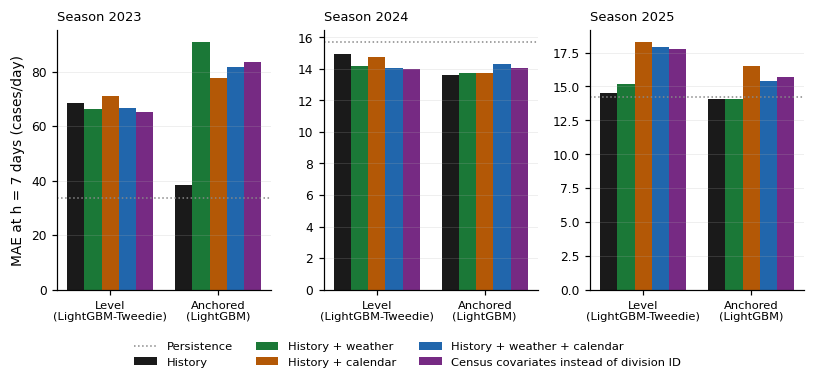

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(FULL_W, 3.1), sharey=False)
sets = ["History", "History + weather", "History + calendar", "History + weather + calendar", "Census covariates instead of division ID"]
cl = ["#1A1A1A", "#1B7837", "#B35806", "#2166AC", "#762A83"]
for a, s in zip(axs, SEASONS):
    q = AB[(AB.season == s) & (AB.h == 7)]
    x = np.arange(2); w = .16
    for i, (fs, c) in enumerate(zip(sets, cl)):
        v = [q[(q.formulation == f) & (q.feature_set == fs)].MAE.iloc[0] for f in ["level", "anchored"]]
        a.bar(x + (i - 2) * w, v, w, color=c, label=fs)
    pers = S[(S.season == s) & (S.h == 7) & (S.model == "Persistence")].MAE.iloc[0]
    a.axhline(pers, color="#888888", ls=":", lw=1, label="Persistence")
    a.set_xticks(x); a.set_xticklabels(["Level\n(LightGBM-Tweedie)", "Anchored\n(LightGBM)"], fontsize=7.5)
    a.set_title(s.replace("S", "Season "), fontsize=8.5, loc="left"); a.grid(alpha=.25, lw=.5, axis="y")
axs[0].set_ylabel("MAE at h = 7 days (cases/day)")
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False, fontsize=7.5, bbox_to_anchor=(.5, -.12))
fig.tight_layout(); savefig(fig, "Fig10_ablation_h7")

## 9. Outbreak early warning
Alert threshold per division = 90th percentile of daily counts in that division's *training* data.
An alert for target day *d* is issued on day *d − h* when the forecast for *d* exceeds the threshold.
Counts (TP/FP/FN) are pooled over the three seasons before computing sensitivity, precision and F1.
Lead time = first observed exceedance date − issue date of the first alert in that division-season
(positive = warning before the threshold was crossed).

In [26]:
AL_MODELS = [PROPOSED, "Random Forest", "Persistence", "Moving average (7 d)"]
AL = []; LEAD = []
for h in HORIZONS:
    D = FEATS[h]
    for s, (a, b) in SEASONS.items():
        T = D[D.date < a].groupby("division").Patients.quantile(.9).clip(lower=1)
        for mname in AL_MODELS:
            P = PRED[(PRED.h == h) & (PRED.season == s) & (PRED.model == mname)].copy()
            P["thr"] = P.division.map(T); P["event"] = P.Patients >= P.thr; P["alert"] = P.pred >= P.thr
            for grp, Q in [("Dhaka", P[P.division == "Dhaka"]), ("Other divisions", P[P.division != "Dhaka"])]:
                AL.append({"h": h, "season": s, "model": mname, "group": grp, "events": int(Q.event.sum()),
                           "TP": int((Q.event & Q.alert).sum()), "FP": int((~Q.event & Q.alert).sum()), "FN": int((Q.event & ~Q.alert).sum())})
            for d, Q in P.groupby("division"):
                if Q.event.any():
                    al = Q[Q.alert]
                    first_ev = Q[Q.event].date.min()
                    LEAD.append({"h": h, "season": s, "model": mname, "division": d, "first_event": str(first_ev.date()),
                                 "lead_days": (first_ev - (al.date.min() - pd.Timedelta(days=h))).days if len(al) else np.nan})
AL = pd.DataFrame(AL); LEAD = pd.DataFrame(LEAD)
ALp = AL.groupby(["h", "model", "group"])[["events", "TP", "FP", "FN"]].sum().reset_index()
ALp["sensitivity"] = ALp.TP / (ALp.TP + ALp.FN); ALp["precision"] = ALp.TP / (ALp.TP + ALp.FP)
ALp["F1"] = 2 * ALp.TP / (2 * ALp.TP + ALp.FP + ALp.FN)
LD = LEAD.groupby(["h", "model"]).lead_days.agg(["median", "mean", "count"]).reset_index()
LD["share_positive_lead"] = LEAD.groupby(["h", "model"]).lead_days.apply(lambda v: (v > 0).mean()).values
AL.to_csv(os.path.join(TAB, "T10_alerts_by_season.csv"), index=False); ALp.to_csv(os.path.join(TAB, "T10_alerts_pooled.csv"), index=False)
LEAD.to_csv(os.path.join(TAB, "T10b_alert_lead_time.csv"), index=False)
R["alerts"] = {"pooled": ALp.round(4).to_dict(orient="records"), "lead_time_summary": LD.round(2).to_dict(orient="records"),
               "lead_time_dhaka": LEAD[LEAD.division == "Dhaka"].to_dict(orient="records")}
print(LD.round(1).to_string())
ALp.set_index(["h", "group", "model"]).round(3)

     h                        model  median  mean  count  share_positive_lead
0    1  Anchored LightGBM (history)   -10.0 -11.0     11                  0.0
1    1         Moving average (7 d)   -12.5 -12.6     10                  0.0
2    1                  Persistence     0.0   0.0     15                  0.0
3    1                Random Forest    -8.0 -14.2     13                  0.0
4    7  Anchored LightGBM (history)    -4.0 -10.2     15                  0.1
5    7         Moving average (7 d)   -12.5 -12.7     10                  0.0
6    7                  Persistence     0.0   0.0     15                  0.0
7    7                Random Forest     0.0  -2.8     14                  0.1
8   14  Anchored LightGBM (history)    -1.0  -8.2     13                  0.2
9   14         Moving average (7 d)    -9.0 -10.9      9                  0.0
10  14                  Persistence     0.0   0.0     14                  0.0
11  14                Random Forest     0.0   3.1     14        

events    TP   FP   FN  \
h  group           model                                                 
1  Dhaka           Anchored LightGBM (history)     149   135    2   14   
   Other divisions Anchored LightGBM (history)    1209  1064   46  145   
   Dhaka           Moving average (7 d)            149   143    6    6   
   Other divisions Moving average (7 d)           1209  1093   64  116   
   Dhaka           Persistence                     149   142    7    7   
   Other divisions Persistence                    1209  1090  118  119   
   Dhaka           Random Forest                   149    86    0   63   
   Other divisions Random Forest                  1209  1095   74  114   
7  Dhaka           Anchored LightGBM (history)     148   131    1   17   
   Other divisions Anchored LightGBM (history)    1209  1065   60  144   
   Dhaka           Moving average (7 d)            148   137   11   11   
   Other divisions Moving average (7 d)           1209  1054   90  155   
   Dhaka           Persistence                     148   140    8    8   
   Other divisions Persistence                    1209  1088  101  121   
   Dhaka           Random Forest                   148   137    1   11   
   Other divisions Random Forest                  1209  1105  134  104   
14 Dhaka           Anchored LightGBM (history)     148   132    3   16   
   Other divisions Anchored LightGBM (history)    1198   995   69  203   
   Dhaka           Moving average (7 d)            148   130   18   18   
   Other divisions Moving average (7 d)           1198  1012  119  186   
   Dhaka           Persistence                     148   133   15   15   
   Other divisions Persistence                    1198  1039  123  159   
   Dhaka           Random Forest                   148   121    1   27   
   Other divisions Random Forest                  1198  1070  222  128   

                                                sensitivity  precision     F1  
h  group           model                                                       
1  Dhaka           Anchored LightGBM (history)        0.906      0.985  0.944  
   Other divisions Anchored LightGBM (history)        0.880      0.959  0.918  
   Dhaka           Moving average (7 d)               0.960      0.960  0.960  
   Other divisions Moving average (7 d)               0.904      0.945  0.924  
   Dhaka           Persistence                        0.953      0.953  0.953  
   Other divisions Persistence                        0.902      0.902  0.902  
   Dhaka           Random Forest                      0.577      1.000  0.732  
   Other divisions Random Forest                      0.906      0.937  0.921  
7  Dhaka           Anchored LightGBM (history)        0.885      0.992  0.936  
   Other divisions Anchored LightGBM (history)        0.881      0.947  0.913  
   Dhaka           Moving average (7 d)               0.926      0.926  0.926  
   Other divisions Moving average (7 d)               0.872      0.921  0.896  
   Dhaka           Persistence                        0.946      0.946  0.946  
   Other divisions Persistence                        0.900      0.915  0.907  
   Dhaka           Random Forest                      0.926      0.993  0.958  
   Other divisions Random Forest                      0.914      0.892  0.903  
14 Dhaka           Anchored LightGBM (history)        0.892      0.978  0.933  
   Other divisions Anchored LightGBM (history)        0.831      0.935  0.880  
   Dhaka           Moving average (7 d)               0.878      0.878  0.878  
   Other divisions Moving average (7 d)               0.845      0.895  0.869  
   Dhaka           Persistence                        0.899      0.899  0.899  
   Other divisions Persistence                        0.867      0.894  0.881  
   Dhaka           Random Forest                      0.818      0.992  0.896  
   Other divisions Random Forest                      0.893      0.828  0.859

## 10. Calibrated uncertainty: season-ahead conformalized quantile regression (CQR)
Quantile LightGBM models give a raw interval; the conformal correction (Romano et al., 2019) is estimated from the
*previous* season's out-of-sample errors, as an agency could do in practice (S2024 calibrated with S2023, S2025 with S2024).
Two spaces: **level** (quantiles of the count, full features) and **anchored** (quantiles of the log growth ratio *z*,
history features; interval = exp(anchor + quantile) − 1, conformal scores computed on the *z* scale, so widths scale
with the current level). Pooled and division-wise (Mondrian) calibration, nominal 90 % and 95 %.

In [27]:
def qlgb(alpha):
    return LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=300, max_depth=6, learning_rate=.05,
                         min_child_samples=20, random_state=RNG, verbosity=-1)
QP = []
for h in HORIZONS:
    D = FEATS[h]
    for s, (a, b) in SEASONS.items():
        tr = D[D.date < a]; te = D[(D.date >= a) & (D.date <= b)]
        row = te[["date", "division", "Patients", "anchor", "z"]].assign(h=h, season=s)
        for nominal, (lo_a, hi_a) in {90: (.05, .95), 95: (.025, .975)}.items():
            row[f"L_lo{nominal}"] = qlgb(lo_a).fit(tr[FULL], tr.Patients).predict(te[FULL])
            row[f"L_hi{nominal}"] = qlgb(hi_a).fit(tr[FULL], tr.Patients).predict(te[FULL])
            row[f"A_lo{nominal}"] = qlgb(lo_a).fit(tr[ANCH_HIST], tr.z).predict(te[ANCH_HIST])
            row[f"A_hi{nominal}"] = qlgb(hi_a).fit(tr[ANCH_HIST], tr.z).predict(te[ANCH_HIST])
        QP.append(row)
QP = pd.concat(QP, ignore_index=True)

def qhat(scores, alpha):
    n = len(scores); k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return np.sort(np.asarray(scores))[k - 1]

def interval(test, calib, space, nominal, mode):
    alpha = 1 - nominal / 100
    tgt = "Patients" if space == "L" else "z"
    lo_t, hi_t = test[f"{space}_lo{nominal}"].values, np.maximum(test[f"{space}_hi{nominal}"].values, test[f"{space}_lo{nominal}"].values)
    if mode == "raw":
        q = 0.0
    else:
        sc = np.maximum(calib[f"{space}_lo{nominal}"] - calib[tgt], calib[tgt] - calib[f"{space}_hi{nominal}"])
        if mode == "pooled": q = qhat(sc, alpha)
        else: q = test.division.map(calib.assign(sc=sc).groupby("division").sc.apply(lambda v: qhat(v, alpha))).values
    lo, hi = lo_t - q, hi_t + q
    if space == "A": lo, hi = np.expm1(test.anchor.values + lo), np.expm1(test.anchor.values + hi)
    return np.clip(lo, 0, None), np.clip(hi, 0, None)

CQ = []; BANDS = None
MODES = {"raw": "Quantile regression (raw)", "pooled": "CQR pooled", "mondrian": "CQR by division (Mondrian)"}
for h in HORIZONS:
    for s_te, s_cal in [("S2024", "S2023"), ("S2025", "S2024")]:
        te = QP[(QP.h == h) & (QP.season == s_te)].reset_index(drop=True); ca = QP[(QP.h == h) & (QP.season == s_cal)]
        for space, sname in [("L", "level"), ("A", "anchored")]:
            for nominal in (90, 95):
                for mode, mlab in MODES.items():
                    lo, hi = interval(te, ca, space, nominal, mode)
                    cov = (te.Patients.values >= lo) & (te.Patients.values <= hi)
                    for grp, msk in [("All", np.ones(len(te), bool)), ("Dhaka", te.division.values == "Dhaka"),
                                     ("Other divisions", te.division.values != "Dhaka")]:
                        CQ.append({"h": h, "season": s_te, "space": sname, "nominal": nominal, "method": mlab, "group": grp,
                                   "coverage": cov[msk].mean(), "mean_width": (hi - lo)[msk].mean(),
                                   "median_width": np.median((hi - lo)[msk])})
                    if h == 7 and s_te == "S2025" and nominal == 90 and space == "A" and mode == "mondrian":
                        BANDS = te.assign(lo=lo, hi=hi)
CQ = pd.DataFrame(CQ); CQ.to_csv(os.path.join(TAB, "T11_conformal_intervals.csv"), index=False)
R["intervals"] = {"table": CQ.round(4).to_dict(orient="records")}
CQ[CQ.group == "All"].pivot_table(index=["space", "nominal", "method"], columns=["h", "season"], values=["coverage"]).round(3)

coverage                       \
h                                                 1             7           
season                                         S2024  S2025  S2024  S2025   
space    nominal method                                                     
anchored 90      CQR by division (Mondrian)    0.853  0.869  0.921  0.874   
                 CQR pooled                    0.851  0.889  0.922  0.874   
                 Quantile regression (raw)     0.790  0.786  0.831  0.784   
         95      CQR by division (Mondrian)    0.927  0.924  0.962  0.923   
                 CQR pooled                    0.928  0.938  0.961  0.927   
                 Quantile regression (raw)     0.844  0.842  0.877  0.846   
level    90      CQR by division (Mondrian)    0.871  0.923  0.946  0.923   
                 CQR pooled                    0.939  0.936  0.976  0.937   
                 Quantile regression (raw)     0.836  0.865  0.823  0.867   
         95      CQR by division (Mondrian)    0.943  0.967  0.987  0.981   
                 CQR pooled                    1.000  0.957  0.999  0.977   
                 Quantile regression (raw)     0.910  0.905  0.909  0.931   

                                                           
h                                               14         
season                                       S2024  S2025  
space    nominal method                                    
anchored 90      CQR by division (Mondrian)  0.948  0.899  
                 CQR pooled                  0.949  0.893  
                 Quantile regression (raw)   0.801  0.808  
         95      CQR by division (Mondrian)  0.975  0.940  
                 CQR pooled                  0.972  0.937  
                 Quantile regression (raw)   0.870  0.846  
level    90      CQR by division (Mondrian)  0.977  0.945  
                 CQR pooled                  0.982  0.954  
                 Quantile regression (raw)   0.816  0.894  
         95      CQR by division (Mondrian)  0.997  0.969  
                 CQR pooled                  0.999  0.963  
                 Quantile regression (raw)   0.918  0.931

In [28]:
CQ[(CQ.group == "All") & (CQ.nominal == 90)].pivot_table(index=["space", "method"], columns=["h", "season"], values="mean_width").round(1)

h                                       1            7            14       
season                               S2024 S2025  S2024 S2025  S2024  S2025
space    method                                                            
anchored CQR by division (Mondrian)   64.2  89.5   86.1  74.7  146.1   94.3
         CQR pooled                   56.1  74.7   86.1  69.2  139.0   88.3
         Quantile regression (raw)    49.5  55.3   47.8  50.5   59.9   64.3
level    CQR by division (Mondrian)  181.0  73.8  173.1  80.3  198.4  104.9
         CQR pooled                   69.5  69.8   90.8  70.9  130.7   87.7
         Quantile regression (raw)    57.7  64.1   54.1  65.5   62.9   79.5

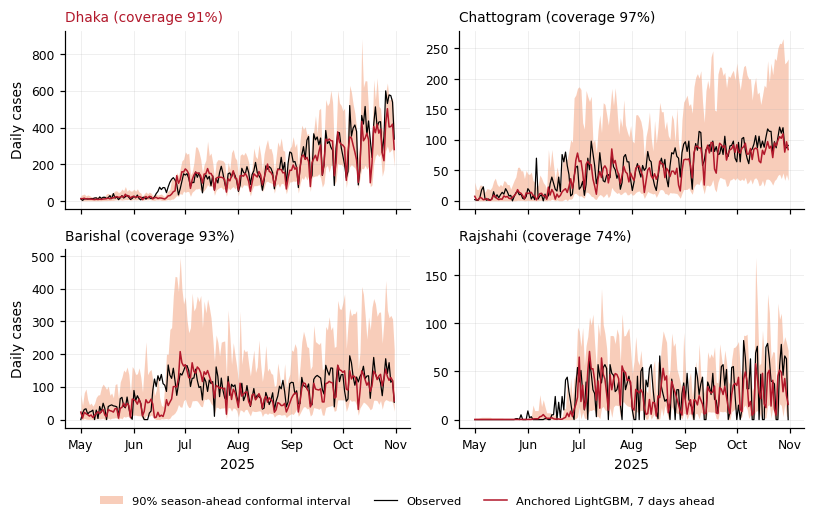

In [29]:
# Prospective 2025 forecasts (h = 7) with 90% anchored Mondrian-CQR bands for four divisions across the gradient
P7 = PRED[(PRED.h == 7) & (PRED.season == "S2025") & (PRED.model == PROPOSED)]
show_divs = ["Dhaka", "Chattogram", "Barishal", "Rajshahi"]
fig, axs = plt.subplots(2, 2, figsize=(FULL_W, 4.6), sharex=True)
for a, d in zip(axs.ravel(), show_divs):
    q = BANDS[BANDS.division == d].sort_values("date"); p = P7[P7.division == d].sort_values("date")
    a.fill_between(q.date, q.lo, q.hi, color="#F4A582", alpha=.55, lw=0, label="90% season-ahead conformal interval")
    a.plot(p.date, p.Patients, color="black", lw=.8, label="Observed")
    a.plot(p.date, p.pred, color=URBAN_C, lw=1.0, label="Anchored LightGBM, 7 days ahead")
    cov = ((q.Patients >= q.lo) & (q.Patients <= q.hi)).mean()
    a.set_title(f"{d} (coverage {cov:.0%})", loc="left", fontsize=9, color=URBAN_C if d == "Dhaka" else "black"); a.grid(alpha=.25, lw=.5)
    a.xaxis.set_major_locator(mdates.MonthLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axs[0, 0].set_ylabel("Daily cases"); axs[1, 0].set_ylabel("Daily cases"); axs[1, 0].set_xlabel("2025"); axs[1, 1].set_xlabel("2025")
h_, l_ = axs[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False, fontsize=7.5, bbox_to_anchor=(.5, -.03))
fig.tight_layout(rect=(0, .03, 1, 1)); savefig(fig, "Fig11_prospective_2025_intervals")

## 11. Export everything used in the manuscript

In [30]:
def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    if isinstance(o, (pd.Timestamp,)): return str(o.date())
    return o
with open(os.path.join(RES, "cei_results.json"), "w") as f: json.dump(to_jsonable(R), f, indent=1)
print("Saved:", os.path.join(RES, "cei_results.json"))
for root, _, files in os.walk(BASE_OUT):
    for fn in sorted(files): print(os.path.relpath(os.path.join(root, fn), BASE_OUT))

Saved: /kaggle/working/outputs/results/cei_results.json
tables/T10_alerts_by_season.csv
tables/T10_alerts_pooled.csv
tables/T10b_alert_lead_time.csv
tables/T11_conformal_intervals.csv
tables/T2_urban_gradient.csv
tables/T2b_dhaka_city_vs_rest.csv
tables/T3_season_timing.csv
tables/T4_dhaka_leadlag.csv
tables/T5_climate_lag_correlations.csv
tables/T7_season_ahead_by_season.csv
tables/T7_season_ahead_mean_over_seasons.csv
tables/T7b_prospective_2025.csv
tables/T7c_extrapolation_diagnostic.csv
tables/T8_division_skill.csv
tables/T8b_bootstrap_ci.csv
tables/T9_ablation.csv
tables/division_covariates.csv
results/cei_results.json
results/season_ahead_predictions.csv.gz
figures/Fig10_ablation_h7.pdf
figures/Fig10_ablation_h7.png
figures/Fig10_ablation_h7.tiff
figures/Fig11_prospective_2025_intervals.pdf
figures/Fig11_prospective_2025_intervals.png
figures/Fig11_prospective_2025_intervals.tiff
figures/Fig3_weekly_series_regimes.pdf
figures/Fig3_weekly_series_regimes.png
figures/Fig3_weekly_ser